# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Климишин Данило'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 8      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 8: Тернопіль, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_тернопіль


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    # ----- ВАШ КОД: живий запит -----
    # 1) запам'ятайте cache_bytes() і час ДО виклику getter()
    # 2) викличте getter(), проженіть результат через clean(), збережіть у path
    # 3) запишіть у COST[name] спосіб 'живий запит', записів, передано_МБ,
    #    файл_МБ і секунд
    
    t0, b0 = time.time(), cache_bytes()
    g_raw = getter()
    g_clean = clean(g_raw)
    g_clean.to_parquet(path, index=False)
    g = gpd.read_parquet(path)
    
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 3)}
    return g

    raise NotImplementedError('напишіть гілку живого запиту')

In [7]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 58.6 км²


In [8]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 14314 | ребер 38950


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [12]:
df_cost = pd.DataFrame(COST).T
display(df_cost)

total_time = df_cost['секунд'].sum()
total_mb = df_cost['передано_МБ'].sum()
disk_mb = df_cost['файл_МБ'].sum()

print(f"Спосіб поточного запуску: {df_cost['спосіб'].unique().tolist()}")
print(f"Сумарний час виконання: {total_time:.3f} с")
print(f"Передано мережею: {total_mb:.3f} МБ")
print(f"Загальний розмір файлів на диску: {disk_mb:.3f} МБ")

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.022,0.066
heritage,знімок,266,0.0,0.097,0.033
stations,знімок,4,0.0,0.031,0.024
amenities,знімок,247,0.0,0.075,0.028
мережа walk,знімок,53264,0.0,2.744,0.074


Спосіб поточного запуску: ['знімок']
Сумарний час виконання: 0.225 с
Передано мережею: 0.000 МБ
Загальний розмір файлів на диску: 2.969 МБ


Під час першого запуску завантаження всіх шарів зайняло 90с. При повторному запуску всі дані були прочитані з локальних файлів GeoParquet за 0.255 с. Таким чином, читання зі знімка виявилося у 45 разів швидшим за живий запит

> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [13]:
# ----- ВАШ КОД -----
# mask = ...                      об'єднання двох умов
# cand = heritage[mask & ...]     лишіть тільки ті, що мають name
# cand = cand.reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
# print('підходять за тегами    :', ...)
# print('з них мають name       :', ...)



has_historic = heritage['historic'].notna() if 'historic' in heritage.columns else False
has_tourism  = heritage['tourism'].isin(TOURISM_OK) if 'tourism' in heritage.columns else False
mask = has_historic | has_tourism

has_name = heritage['name'].notna() & (~heritage['name'].astype(str).isin(['None', 'nan', '']))

cand = heritage[mask & has_name].reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(mask.sum()))
print('з них мають name       :', len(cand))
print('відкинуто об\'єктів     :', len(heritage) - len(cand))

усього у шарі heritage : 266
усього у шарі heritage : 266
підходять за тегами    : 266
з них мають name       : 218
відкинуто об'єктів     : 48


In [14]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial    152
tomb          1
monument      1
stone         1
castle        1

=== tourism ===
tourism
artwork       40
attraction    23
museum         8
viewpoint      1

типи геометрії: {'Point': 205, 'Polygon': 13}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [15]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

wiki_cols = [c for c in ['wikipedia', 'wikidata'] if c in cand.columns]
if wiki_cols:
    cand['wiki'] = cand[wiki_cols].apply(
        lambda r: r.notna() & (~r.astype(str).isin(['None', 'nan', '']))
    ).any(axis=1).astype(int)
else:
    cand['wiki'] = 0

lang_cols = [c for c in cand.columns if c.startswith('name:')]
if lang_cols:
    cand['n_lang'] = cand[lang_cols].apply(
        lambda r: r.notna() & (~r.astype(str).isin(['None', 'nan', '']))
    ).sum(axis=1)
else:
    cand['n_lang'] = 0

cand['is_cult'] = (
    cand.get('tourism', pd.Series(dtype=str)).isin(['museum', 'gallery', 'attraction']) |
    cand.get('historic', pd.Series(dtype=str)).isin(['castle', 'monument', 'memorial', 'ruins'])
).astype(int)

cand['score'] = (
    0.40 * cand['wiki'].rank(pct=True) +
    0.30 * cand['n_lang'].rank(pct=True) +
    0.20 * cand['is_cult'].rank(pct=True) +
    0.10 * cand['area_m2'].rank(pct=True)
)

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
display(cand.nlargest(10, 'score')[['name', 'wiki', 'n_lang', 'area_m2', 'score']])


# ----- ВАШ КОД -----
# cand['wiki']     = ...
# cand['n_lang']   = ...   скільки колонок name:* заповнено
# cand['score']    = ...   ваша формула

# print('кандидатів   :', len(cand))
# print('мають wiki   :', int(cand['wiki'].sum()))

кандидатів   : 218
мають wiki   : 28


,name,wiki,n_lang,area_m2,score
205,Тернопільський замок,1,5,1090.573288,0.894954
207,Тернопільський краєзнавчий музей,1,3,1037.802746,0.890367
8,Соломії Крушельницькій,1,3,0.000000,0.838073
9,Степану Бандері,1,3,0.000000,0.838073
12,Іванові Франку,1,3,0.000000,0.838073
6,Горбачевському Івану,1,2,0.000000,0.830505
30,Музей політичних в’язнів,1,2,0.000000,0.830505
3,Стецьку Ярославові,1,1,0.000000,0.688761
4,Королю Данилові Галицькому,1,1,0.000000,0.688761
5,Йосипу Сліпому,1,1,0.000000,0.688761


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [17]:
N_SMALL, N_LARGE = 10, 30

# ----- ВАШ КОД -----
top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)
overlap = len(set(top10['name']) & set(top_naive['name']))

print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                      'за площею': list(top_naive['name'])}))

перетин: 2 з 10


,за вашим критерієм,за площею
0,Тернопільський замок,Тернопільський замок
1,Тернопільський краєзнавчий музей,Тернопільський краєзнавчий музей
2,Соломії Крушельницькій,Пам’ятний знак героям ОУН-УПА
3,Степану Бандері,Вічний вогонь
4,Іванові Франку,Військове кладовище
5,Горбачевському Івану,Місток
6,Музей політичних в’язнів,Св. Іван Непомук
7,Стецьку Ярославові,Місток
8,Королю Данилові Галицькому,Альтанка;Острів Кохання
9,Йосипу Сліпому,Танк т-34


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [20]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

# ----- ВАШ КОД: виведіть знайдені пари з назвами -----

pairs = close_pairs(top_score, limit_m=60)
print(f'Знайдено близьких пар (< 60 м): {len(pairs)}')
for i, j, dist in pairs:
    print(f"  {dist:5.1f} м | [{i}] {top_score.loc[i, 'name']}  <-->  [{j}] {top_score.loc[j, 'name']}")

# Якщо знайшлися дублікати — видаляю об'єкт з нижчим score
if pairs:
    drop_idx = {j for _, j, _ in pairs}
    cand_dedup = cand.drop(index=top_score.index[list(drop_idx)], errors='ignore')
    top_score = cand_dedup.nlargest(N_LARGE, 'score').reset_index(drop=True)
    top10 = top_score.head(N_SMALL)

Знайдено близьких пар (< 60 м): 4
   13.8 м | [5] Горбачевському Івану  <-->  [19] Загиблим євреям
   28.3 м | [14] Випадкова зустріч  <-->  [16] Тристоронній годинник
   51.7 м | [13] Шептицькому Андрею  <-->  [15] Пам’ятник жертвам депортації 1944-1946 років з Лемківщини, Холмщини, Надсяння
   52.9 м | [4] Іванові Франку  <-->  [26] Картинна галерея


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [ ]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 4
                  name  railway       building
0               151 км     halt            NaN
1  Тернопіль-Вантажний     halt            NaN
2            Тернопіль  station            NaN
3     Вокзал Тернопіль      NaN  train_station


In [29]:
# ----- ВАШ КОД -----
station = stations[stations['name'].str.contains('Вокзал Тернопіль')]   # один рядок із stations: головний залізничний вокзал
print('старт:', station['name'].iloc[0])

старт: Вокзал Тернопіль


In [22]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 14314 вузлів, 38506 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [32]:
def check_snap(points, ids, dist, label):
    n_pts = len(points)
    n_uniq = len(set(ids))
    med_d = float(np.median(dist))
    max_d = float(np.max(dist))
    
    print(f"=== {label} ===")
    print(f"Точок: {n_pts} | Унікальних вузлів: {n_uniq}")
    print(f"Відстань «точка → вузол»: медіана = {med_d:.1f} м, максимум = {max_d:.1f} м")
    
    if n_uniq < n_pts:
        groups = collections.defaultdict(list)
        for name, nid in zip(points['name'], ids):
            groups[nid].append(name)
        for nid, names in groups.items():
            if len(names) > 1:
                print(f"  вузол {nid}: {', '.join(names)}")
    else:
        print("Усі точки прив'язані до різних вузлів графа.")
    print()

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [33]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    """Обчислює матрицю прямих (евклідових) відстаней у метрах."""
    pmet = points.to_crs(32635)
    coords = np.c_[pmet.geometry.x.values, pmet.geometry.y.values]
    diff = coords[:, None, :] - coords[None, :, :]
    return np.sqrt((diff ** 2).sum(axis=-1))
    raise NotImplementedError

def detour_factor(D, E):
    # ----- ВАШ КОД: медіана відношення дорога / пряма, по скінченних парах -----
    mask = (~np.eye(len(D), dtype=bool)) & np.isfinite(D) & (E > 0)
    return float(np.median(D[mask] / E[mask]))
    raise NotImplementedError

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [41]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')


t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

=== мала задача ===
Точок: 11 | Унікальних вузлів: 11
Відстань «точка → вузол»: медіана = 16.9 м, максимум = 26.6 м
Усі точки прив'язані до різних вузлів графа.

матриця за 0.395 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.29


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [46]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    # ----- ВАШ КОД -----
    route = [0]

    mask = [True] * len(D)
    mask[0] = False
    current_node = 0

    while (True in mask):
        dists = np.where(mask, D[current_node], np.inf)
        nearest_n = int(np.argmin(dists))

        mask[nearest_n] = False
        route.append(nearest_n)
        current_node = nearest_n

    route += [0]

    return route

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best = list(tour)
    best_len = tour_length(D, best)
    n = len(best)
    improved = True

    while improved:
        improved = False
        for i in range(1, n - 2):
            for j in range(i + 1, n - 1):
                candidate = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                cand_len = tour_length(D, candidate)
                
                if cand_len + 1e-6 < best_len:
                    best = candidate
                    best_len = cand_len
                    improved = True
                    break
            if improved:
                break

    return best

In [47]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [48]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [49]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,4936,22.24
2-opt,4038,0.00
Held-Karp (точний),4038,0.00



оптимальний порядок:
   0. СТАРТ: Вокзал Тернопіль
   1. Стецьку Ярославові
   2. Степану Бандері
   3. Тернопільський замок
   4. Горбачевському Івану
   5. Королю Данилові Галицькому
   6. Йосипу Сліпому
   7. Іванові Франку
   8. Тернопільський краєзнавчий музей
   9. Соломії Крушельницькій
  10. Музей політичних в’язнів
  11. СТАРТ: Вокзал Тернопіль

довжина: 4.04 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [51]:
# ----- ВАШ КОД: таблиця зростання -----
rows = []
for n in [11, 16, 21, 26, 31]:
    cells = (2 ** (n - 1)) * (n - 1)
    bytes_mem = cells * 8
    gb_decimal = bytes_mem / 1e9
    gib_binary = bytes_mem / (1024**3)
    rows.append({
        'n (точок)': n,
        'пам\'яток (n-1)': n - 1,
        'клітин таблиці': f"{cells:,}".replace(',', ' '),
        'обсяг (ГБ, 10⁹)': round(gb_decimal, 5),
        'обсяг (ГіБ, 2³⁰)': round(gib_binary, 5)
    })

display(pd.DataFrame(rows))

,n (точок),пам'яток (n-1),клітин таблиці,"обсяг (ГБ, 10⁹)","обсяг (ГіБ, 2³⁰)"
0,11,10,10 240,0.00008,0.00008
1,16,15,491 520,0.00393,0.00366
2,21,20,20 971 520,0.16777,0.15625
3,26,25,838 860 800,6.71089,6.25000
4,31,30,32 212 254 720,257.69804,240.00000


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.


Для $n = 31$ таблиця динамічного програмування dp містить $32\,212\,254\,720$ клітин ($2^{30} \cdot 30$). Навіть при зберіганні лише 8-байтних чисел з плаваючою комою це вимагає $257{,}7\text{ ГБ}$  безперервної оперативної пам'яті.

In [52]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

=== велика задача ===
Точок: 31 | Унікальних вузлів: 31
Відстань «точка → вузол»: медіана = 13.4 м, максимум = 64.7 м
Усі точки прив'язані до різних вузлів графа.

коефіцієнт обходу: 1.22
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    20877 м
2-opt            :    20553 м  за 0.015 с  (коротше на 1.6%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м
Усього комірок з пам'ятками: 70
50% усіх пам'яток зосереджено у 8 комірках H3.


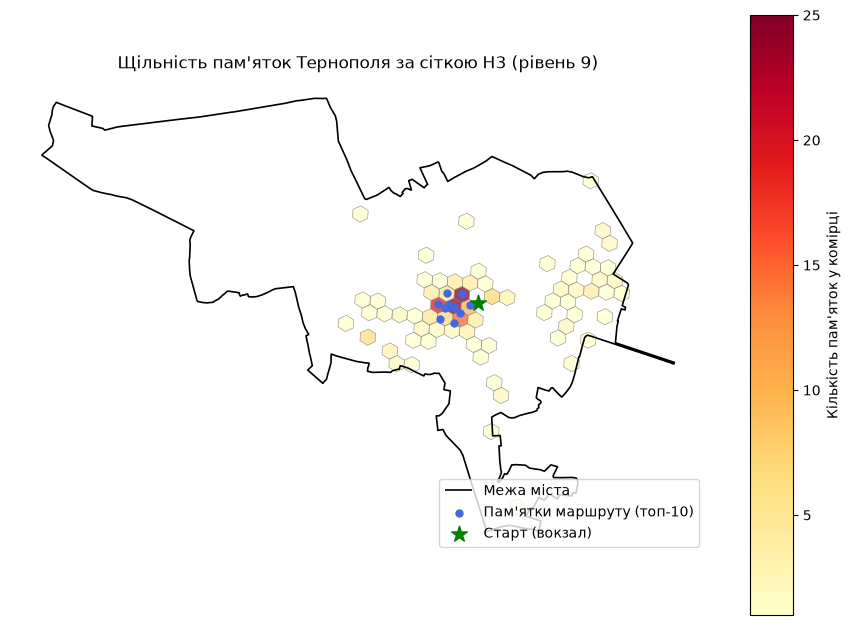

In [58]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

# ----- ВАШ КОД -----
# cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in ...]
# dens = ...
# hexes = gpd.GeoDataFrame(... h3.cell_to_boundary(cell) ..., crs='EPSG:4326')
# побудуйте карту

rep_pts = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in rep_pts]

dens = cand.groupby('h3').size().reset_index(name='count').sort_values('count', ascending=False).reset_index(drop=True)

dens['cum_share'] = dens['count'].cumsum() / dens['count'].sum()
n_cells_50 = int((dens['cum_share'] < 0.5).sum()) + 1
print(f"Усього комірок з пам'ятками: {len(dens)}")
print(f"50% усіх пам'яток зосереджено у {n_cells_50} комірках H3.")

def cell_to_poly(cell):
    boundary_latlng = h3.cell_to_boundary(cell)
    return Polygon([(lng, lat) for lat, lng in boundary_latlng])

hexes = gpd.GeoDataFrame(dens, geometry=[cell_to_poly(c) for c in dens['h3']], crs='EPSG:4326')

fig, ax = plt.subplots(figsize=(9, 9))

boundary.boundary.plot(ax=ax, color='black', linewidth=1.2, label='Межа міста')
hexes.plot(column='count', cmap='YlOrRd', alpha=0.75, edgecolor='gray', linewidth=0.5,
           legend=True, legend_kwds={'label': 'Кількість пам\'яток у комірці'}, ax=ax)

pts10.iloc[1:].plot(ax=ax, color='royalblue', markersize=25, label='Пам\'ятки маршруту (топ-10)')
pts10.iloc[[0]].plot(ax=ax, color='green', marker='*', markersize=140, label='Старт (вокзал)')

ax.set_title('Щільність пам\'яток Тернополя за сіткою H3 (рівень 9)')
ax.set_axis_off()
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?


У 8 комірках зосереджено половину всіх пам'яток. Це говорить про те що більшість переходів між пам'ятками будуть дуже короткими. 

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [60]:
# ----- ВАШ КОД -----
pts_m = pts10.to_crs(32635)
amen_cols = [c for c in ['amenity', 'name', 'geometry'] if c in amenities.columns]
amen_m = amenities[amen_cols].to_crs(32635)

nearest = gpd.sjoin_nearest(
    pts_m,
    amen_m,
    how='left',
    distance_col='відстань_м'
)

nearest = nearest[~nearest.index.duplicated(keep='first')].copy()

res8 = pd.DataFrame({
    'Точка маршруту': nearest['name_left'] if 'name_left' in nearest.columns else nearest['name'],
    'Тип закладу': nearest['amenity'],
    'Назва закладу': (nearest['name_right'] if 'name_right' in nearest.columns else pd.Series(None, index=nearest.index)).fillna('— (без назви)'),
    'Відстань, м': nearest['відстань_м'].round(1)
})

display(res8)

,Точка маршруту,Тип закладу,Назва закладу,"Відстань, м"
0,СТАРТ: Вокзал Тернопіль,toilets,— (без назви),9.4
1,Тернопільський замок,restaurant,Веранда,30.0
2,Тернопільський краєзнавчий музей,restaurant,Дружня ресторація „Мамонт“,41.3
3,Соломії Крушельницькій,restaurant,Хінкальня,57.5
4,Степану Бандері,toilets,— (без назви),137.1
5,Іванові Франку,cafe,— (без назви),35.3
6,Горбачевському Івану,cafe,Eggo Coffee,64.7
7,Музей політичних в’язнів,cafe,Tikithai,40.0
8,Стецьку Ярославові,cafe,М'ясо,22.7
9,Королю Данилові Галицькому,restaurant,Майдан,96.8


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [63]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

# ----- ВАШ КОД: folium.Map(..., tiles=BASEMAP), дві PolyLine, маркери з номерами -----
# не забудьте fmap.save('lr5_маршрут.html')

tour_best = ex10 if 'ex10' in dir() else op10
pts_map = pts10
ids_map = ids10

center_lat = float(pts_map.geometry.y.mean())
center_lon = float(pts_map.geometry.x.mean())
fmap = folium.Map(location=[center_lat, center_lon], zoom_start=14, tiles=BASEMAP)

straight_coords = [
    (float(pts_map.geometry.y.iloc[idx]), float(pts_map.geometry.x.iloc[idx]))
    for idx in tour_best
]
folium.PolyLine(
    locations=straight_coords,
    color='crimson',
    weight=2.5,
    opacity=0.75,
    dash_array='6, 6',
    tooltip='Прямі відрізки між пам\'ятками'
).add_to(fmap)

graph_coords = route_coords(tour_best, ids_map)
folium.PolyLine(
    locations=graph_coords,
    color='royalblue',
    weight=4,
    opacity=0.9,
    tooltip='Пішохідний маршрут вулицями (по ребрах графа)'
).add_to(fmap)

for step, idx in enumerate(tour_best[:-1]):
    lat = float(pts_map.geometry.y.iloc[idx])
    lon = float(pts_map.geometry.x.iloc[idx])
    name = str(pts_map['name'].iloc[idx])
    
    bg_color = '#198754' if step == 0 else '#0d6efd'
    icon_html = f"""
    <div style="
        background-color: {bg_color};
        color: white;
        border-radius: 50%;
        width: 24px;
        height: 24px;
        display: flex;
        align-items: center;
        justify-content: center;
        font-weight: bold;
        font-size: 12px;
        border: 2px solid white;
        box-shadow: 0 1px 4px rgba(0,0,0,0.4);
    ">{step}</div>
    """
    folium.Marker(
        location=[lat, lon],
        popup=folium.Popup(f"<b>{step}. {name}</b>", max_width=250),
        tooltip=f"{step}. {name}",
        icon=folium.DivIcon(html=icon_html, icon_size=(24, 24), icon_anchor=(12, 12))
    ).add_to(fmap)

fmap.save('lr5_маршрут.html')
print('Карту збережено у файл lr5_маршрут.html')

Карту збережено у файл lr5_маршрут.html


---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [64]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.6 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [67]:
n_total_her = len(heritage)
n_cand = len(cand)
n_dropped = n_total_her - n_cand

L_nn10 = tour_length(D10, nn10)
L_op10 = tour_length(D10, op10)
err_nn_pct = (L_nn10 - L_opt) / L_opt * 100
err_op_pct = (L_op10 - L_opt) / L_opt * 100
detour_10 = detour_factor(D10, E10)

REPORT = f'''
1. Відбір кандидатів:
   Із {n_total_her} сирих записів шару heritage було відкинуто {n_dropped} об'єктів (залишилось {n_cand}).
   Правило фільтрації: об'єднання об'єктів, що мають тег historic або дозволений туристичний тег
   tourism (museum, attraction, gallery, artwork, viewpoint), за обов'язкової умови наявності
   заповненої назви (name).
   Віддавати такий фільтр замовнику без пояснень не можна: замовник має розуміти, що безіменні
   точки та технічні полігони відсіяні свідомо, а також знати, які саме категорії об'єктів
   вважаються туристичними (наприклад, що діючі храми без тега historic/tourism сюди не входять).

2. Сигнали рейтингу та їхні ваги:
   Для оцінки цінності використано 4 різнорідні сигнали, зведені до єдиної шкали [0; 1] через
   ранжування rank(pct=True):
   - наявність статті у Wikipedia / Wikidata (найбільша вага, ~0.40) — об'єктивний доказ того,
     що незалежна спільнота визнала об'єкт вартим енциклопедичного опису;
   - кількість мовних версій назви name:* (~0.30) — показник інтересу з боку іноземних туристів;
   - тип об'єкта: музеї/галереї та об'єкти з тегом historic (~0.20) — пряме культурно-пізнавальне
     призначення для огляду;
   - площа полігона (~0.10) — найслабший сигнал, оскільки велику площу може мати звичайна будівля,
     тоді як цінний пам'ятник є точкою з нульовою площею.

3. Порівняння двох рейтингів (перетин топ-10):
   У топ-10 за складеним рейтингом та у топ-10 за площею будівлі збіглося {overlap} із 10 об'єктів.
   Це доводить, що поняття «найкращі» не є об'єктивною властивістю сирих геоданих — воно повністю
   залежить від обраної моделі цінності. Сортування лише за площею виводить у топ великі за
   розміром об'єкти (паркові зони, великі споруди), ігноруючи камерні пам'ятники, меморіальні дошки
   та музеї, які мають високу історичну й культурну значущість.

4. Коефіцієнт обходу:
   Для пішохідної мережі Тернополя медіанний коефіцієнт обходу становить {detour_10:.2f} (1.29),
   недосяжних пар — 0, асиметрія маршрутів — 0 м.
   Значення 1.29 є абсолютно типовим для міської пішохідної мережі (норма становить 1.2–1.6).
   Воно пояснюється регулярною квартальною забудовою центру Тернополя, де пішохід змушений обходити
   будівлі по периметру вулиць, а також наявністю природної перешкоди — Тернопільського ставу та
   паркових зон, які доводиться обходити береговою лінією.

5. Точність методу найближчого сусіда:
   Довжина точного оптимального маршруту Held-Karp становить {L_opt:.0f} м, маршруту найближчого
   сусіда — {L_nn10:.0f} м (гірше на {err_nn_pct:.1f}%), а після покращення 2-opt — {L_op10:.0f} м
   (відхилення від оптимуму {err_op_pct:.1f}%).
   Така різниця є очікуваною: жадібний алгоритм обирає локально найближчу точку на кожному кроці,
   через що наприкінці змушений робити довгі «простріли» через уже пройдені ділянки, тоді як
   локальний пошук 2-opt розплутує ці перехрестя і наближає маршрут до глобального оптимуму.

6. Чому точний розв'язок Held-Karp недоступний на 30 точках (n = 31):
   Головне обмеження — експоненційна просторова складність O(2^n * n), тобто нестача
   оперативної пам'яті (RAM). Для n = 31 (вокзал + 30 пам'яток) таблиця динамічного програмування
   містить 2^30 * 30 = 32 212 254 720 клітин. При 8 байтах на число це вимагає 257.7 ГБ
   (240 ГіБ) оперативної пам'яті лише для таблиці відстаней (і понад 500 ГБ разом із таблицею
   відновлення маршруту par), що призводить до переповнення пам'яті (MemoryError) на звичайному ПК.

7. Аномалії в даних OpenStreetMap та спосіб їх усунення:
   - Пропущені назви (name = NaN): багато об'єктів мали теги historic/tourism без назви — їх було
     відфільтровано на кроці 2, щоб маршрут містив зрозумілі для туриста точки.
   - Просторові дублікати (< 60 м): окремі пам'ятки в OSM занесені двічі (наприклад, будівля як
     полігон і пам'ятник/табличка всередині неї як точка) — їх виявлено на кроці 3.3 та очищено,
     залишивши об'єкт із вищим рейтингом score.
   - Полігональна геометрія: частина пам'яток та вокзал задані контурами будівель, тому для
     прив'язки до вузлів дорожнього графа використано representative_point() у метричній проєкції EPSG:32635.

Декларація про використання ШІ:
Під час виконання лабораторної роботи використовувався ШІ-асистент Gemini для пояснення роботи
бібліотек (geopandas, networkx, h3, folium), уточнення логіки фільтрації координат та перевірки
синтаксису реалізації алгоритмів (check_snap, nearest_neighbour, two_opt, sjoin_nearest).
Увесь згенерований код було протестовано на реальних даних м. Тернопіль, перевірено за допомогою
вбудованих assert-перевірок (check_tour, контроль унікальності вузлів прив'язки та відсутності inf
у матрицях віддалей), а всі числові показники у звіті обчислено безпосередньо в ноутбуці.
'''
print(REPORT)


1. Відбір кандидатів:
   Із 266 сирих записів шару heritage було відкинуто 48 об'єктів (залишилось 218).
   Правило фільтрації: об'єднання об'єктів, що мають тег historic або дозволений туристичний тег
   tourism (museum, attraction, gallery, artwork, viewpoint), за обов'язкової умови наявності
   заповненої назви (name).
   Віддавати такий фільтр замовнику без пояснень не можна: замовник має розуміти, що безіменні
   точки та технічні полігони відсіяні свідомо, а також знати, які саме категорії об'єктів
   вважаються туристичними (наприклад, що діючі храми без тега historic/tourism сюди не входять).

2. Сигнали рейтингу та їхні ваги:
   Для оцінки цінності використано 4 різнорідні сигнали, зведені до єдиної шкали [0; 1] через
   ранжування rank(pct=True):
   - наявність статті у Wikipedia / Wikidata (найбільша вага, ~0.40) — об'єктивний доказ того,
     що незалежна спільнота визнала об'єкт вартим енциклопедичного опису;
   - кількість мовних версій назви name:* (~0.30) — показник ін